In [1]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm


from cmfa.emu_example import ordered_ilr_func


In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"
PLOT_DIR = Path("..") / "figures"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_id = np.load(RESULTS_DIR / "true_composition.npy")
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")


True flux: [100. 110.  50.  20.  20.  80.]
True isotopologue distribution: [6.34920635e-05 8.00761905e-01 1.98285714e-01 8.88888889e-04]


In [4]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy")
free_fluxes.shape

(121, 2)

Note that index number 60 is the true flux:

In [ ]:
target = np.array([true_flux[2], true_flux[4]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([50., 20.], dtype=float64)

In [6]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_msts.shape

(121, 50, 4)

In [7]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy")

In [8]:
gini_indices = jnp.load(RESULTS_DIR / "gini_indices.npy")

In [9]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)
estimated_fluxes["trad"].shape

(121, 50, 6)

In [10]:
with open(RESULTS_DIR / "estimated_fluxes_ci.pkl", "rb") as f:
    estimated_fluxes_ci = pickle.load(f)
estimated_fluxes_ci["trad"].shape

(121, 50, 2, 2)

In [ ]:
flux_ci_trad = estimated_fluxes_ci["trad"][true_flux_index,:,:,:].mean(axis=0)
flux_ci_ilr = estimated_fluxes_ci["ilr"][true_flux_index,:,:,:].mean(axis=0)

In [12]:
flux = ["v3", "v5"]
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v3     |          0.0018 |   17746848.5390
v5     |          4.1519 |        102.0622


In [13]:
flux = ["v3", "v5"]
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v3     |         20.5938 |        123.1594
v5     |         14.3223 |         28.7028


In [14]:
with open(RESULTS_DIR / "hessian_matrices.pkl", "rb") as f:
    hessian_matrices = pickle.load(f)
hessian_matrices["trad"].shape

(121, 50, 2, 2)

In [15]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)
estimated_ids["trad"].shape

(121, 50, 4)

In [16]:
resid_trad = free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, [2, 4]]
resid_clr = free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, [2, 4]] 
resid_ilr = free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, [2, 4]]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([235.74365502,   2.56192227], dtype=float64),
 Array([181.44777442,   2.52252032], dtype=float64),
 Array([181.08357372,   2.51852036], dtype=float64))

In [17]:
id_resid_trad = estimated_ids["trad"] - true_ids[:, None, :]
id_resid_clr = estimated_ids["clr"] - true_ids[:, None, :]
id_resid_ilr = estimated_ids["ilr"] - true_ids[:, None, :]

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0, 1))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0, 1))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0, 1))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([6.56973592e-10, 5.05612871e-04, 5.03336899e-04, 2.75660118e-08],      dtype=float64),
 Array([3.65994621e-10, 4.85411688e-04, 4.82330881e-04, 1.85690045e-08],      dtype=float64),
 Array([3.64573978e-10, 4.84278675e-04, 4.81186232e-04, 1.85584164e-08],      dtype=float64))

In [18]:
true_ilrs = ordered_ilr_func(true_ids)
trad_ilrs = ordered_ilr_func(estimated_ids["trad"])
clr_ilrs = ordered_ilr_func(estimated_ids["clr"])
ilr_ilrs = ordered_ilr_func(estimated_ids["ilr"])

ilr_resid_trad = trad_ilrs - true_ilrs[:, None, :]
ilr_resid_clr = clr_ilrs - true_ilrs[:, None, :]
ilr_resid_ilr = ilr_ilrs - true_ilrs[:, None, :]

ilr_mse_trad = (ilr_resid_trad ** 2).mean(axis=(0, 1))
ilr_mse_clr = (ilr_resid_clr ** 2).mean(axis=(0, 1))
ilr_mse_ilr = (ilr_resid_ilr ** 2).mean(axis=(0, 1))

ilr_mse_trad, ilr_mse_clr, ilr_mse_ilr

(Array([2.84412287, 0.48205668, 1.3868094 ], dtype=float64),
 Array([0.0063901 , 0.0092757 , 0.00418271], dtype=float64),
 Array([0.00636234, 0.00927031, 0.00415869], dtype=float64))

In [19]:
(id_resid_trad ** 2).mean(axis=(0, 1))

Array([6.56973592e-10, 5.05612871e-04, 5.03336899e-04, 2.75660118e-08],      dtype=float64)

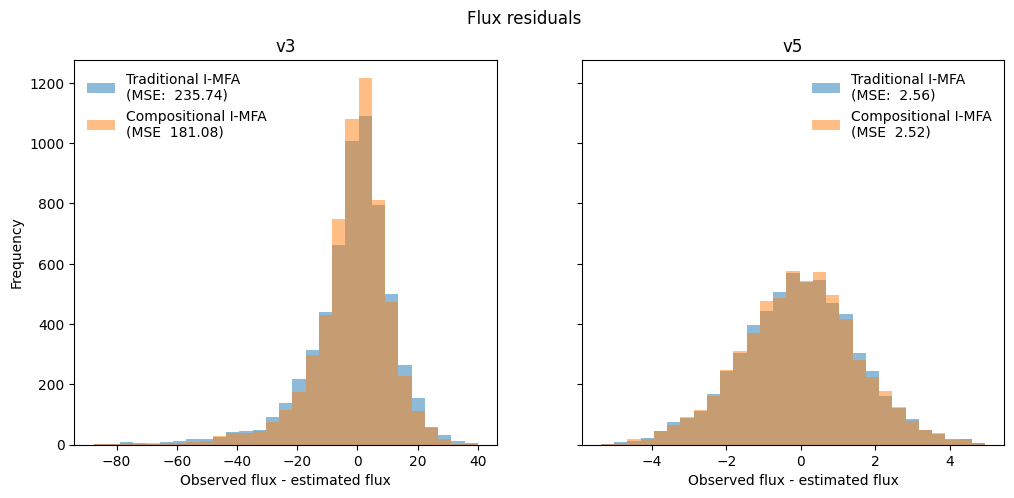

In [20]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

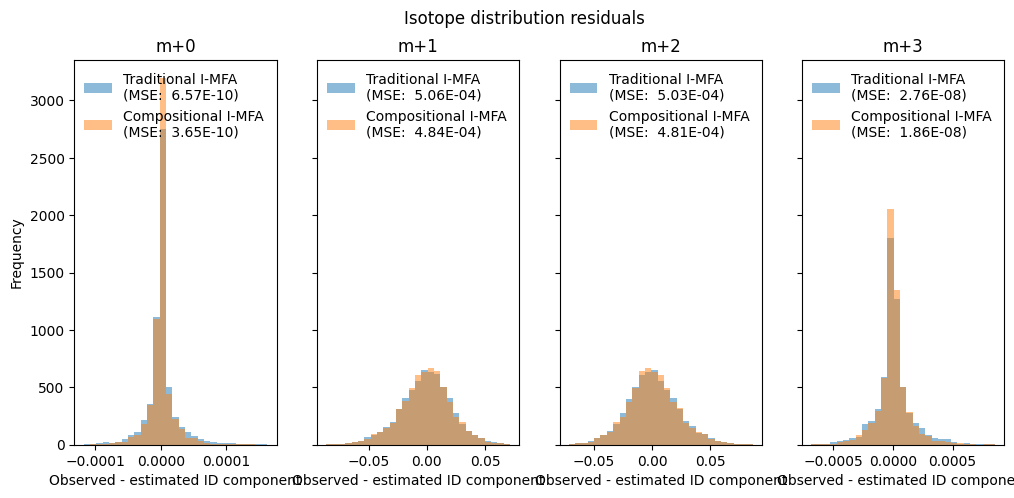

In [21]:
f, axes = plt.subplots(1, 4, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, :, i].flatten()
    resid_comp_i = id_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {id_mse_ilr[i]: .2E})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}", xlabel="Observed - estimated ID component")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Isotope distribution residuals");

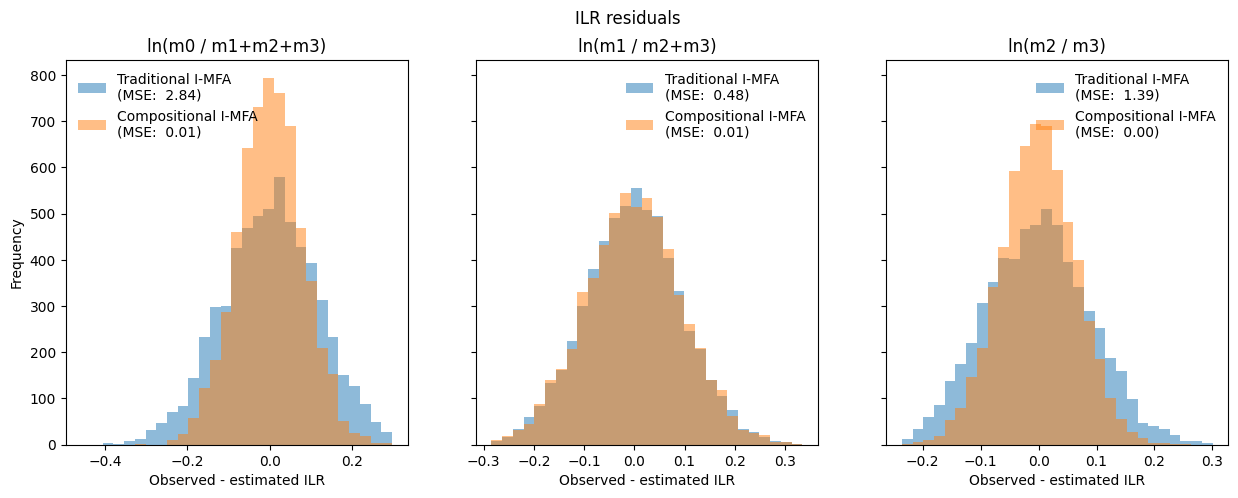

In [22]:
ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"ln({ratio_lhs_i} / {ratio_rhs_i})" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True)

for (i, ax), label in zip(enumerate(axes), labels):
    resid_trad_i = ilr_resid_trad[:, :, i].flatten()
    resid_comp_i = ilr_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.00185)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.998)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {ilr_mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {ilr_mse_ilr[i]: .2f})" 
    )
    ax.set(title=label, xlabel="Observed - estimated ILR")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.suptitle("ILR residuals");

**Figure caption** Traditional vs Compositional I-MFA flux estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

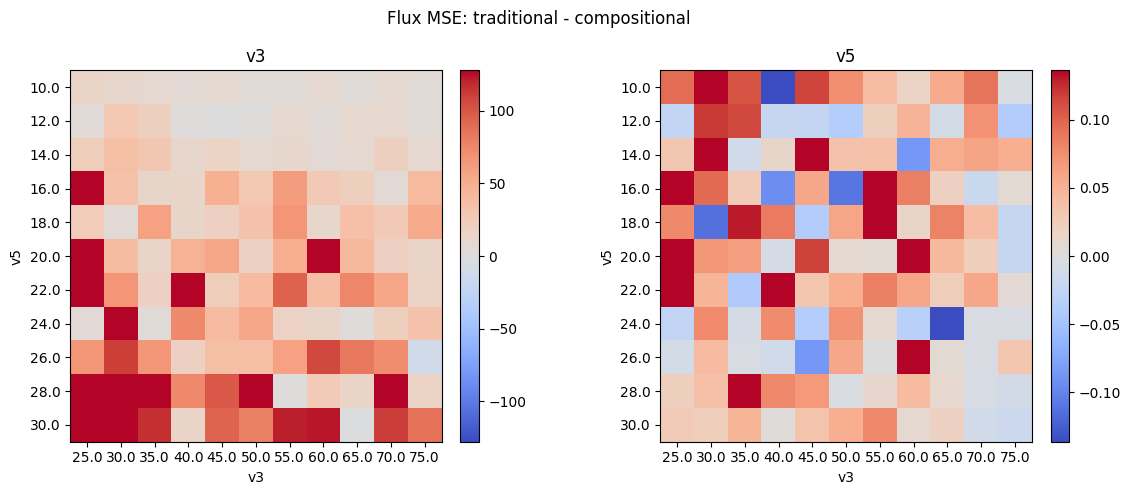

In [23]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1)

for i in range(2):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")

f.tight_layout()

In [24]:
diff_flux = (resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1)
gini = jnp.column_stack((gini_indices, diff_flux))

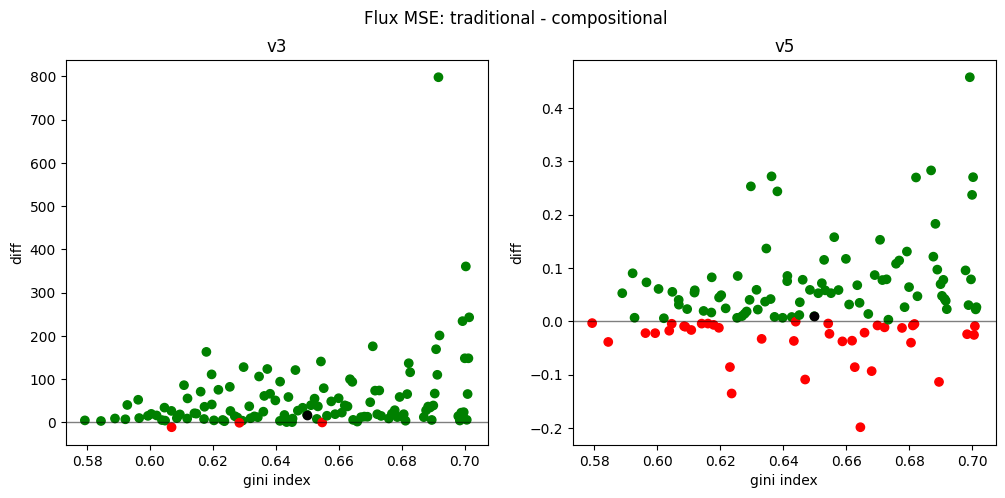

In [61]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

for i in range(2):
    y_values = gini[:, i+1]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(gini[:,0], y_values, c=colors)
    axes[i].scatter(gini[true_flux_index,0], y_values[true_flux_index], color="black")
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="gini index", ylabel="diff", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")
plt.show()


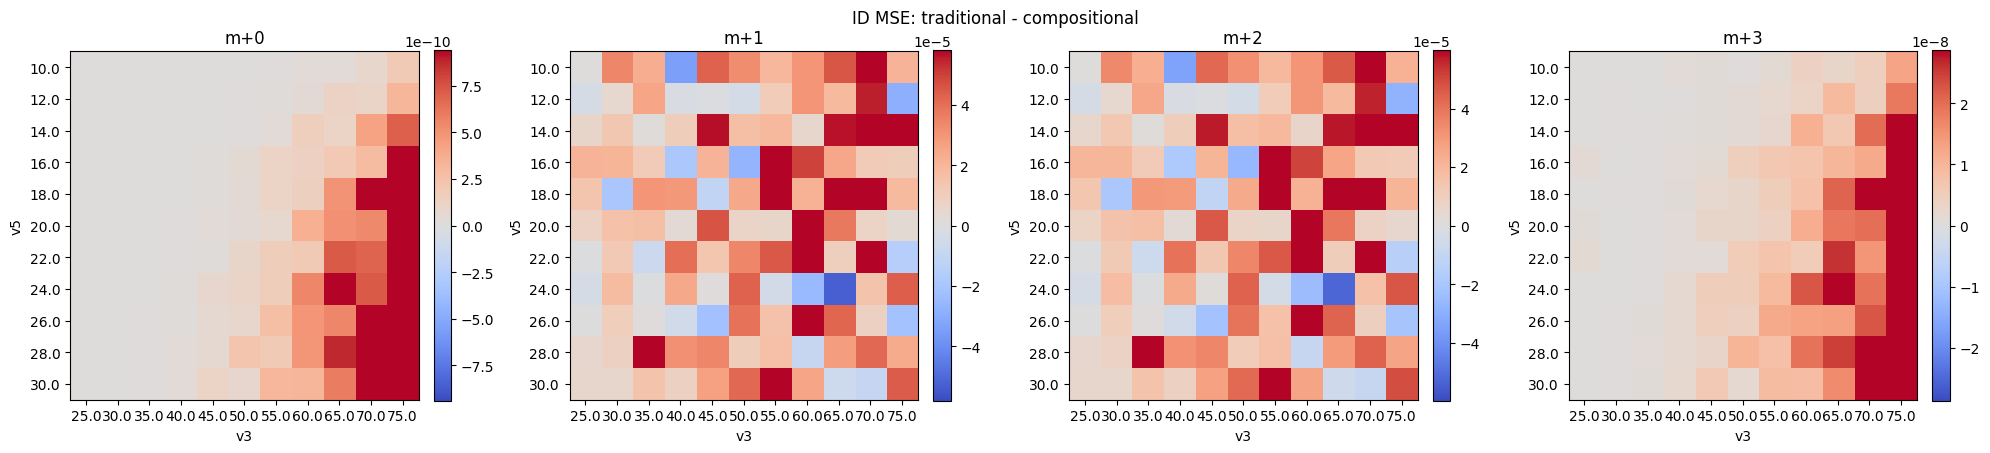

In [26]:
f, axes = plt.subplots(1, 4, figsize=[20, 8])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff_id = (id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1)

for i in range(4):
    halfrange = np.quantile(np.abs(diff_id[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff_id[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"m+{i}")
f.suptitle("ID MSE: traditional - compositional", y=0.75);
f.tight_layout()

In [27]:
gini_id = jnp.column_stack((gini_indices, diff_id))

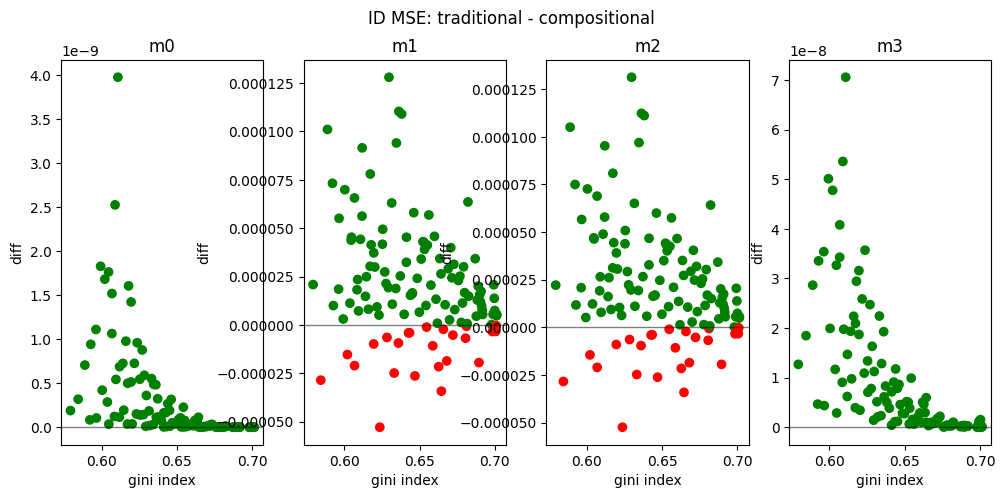

In [33]:
f, axes = plt.subplots(1, 4, figsize=[12, 5])
axes = axes.ravel()

for i in range(4):
    y_values = gini_id[:, i+1]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(gini_id[:,0], y_values, c=colors)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="gini index", ylabel="diff", title=f"m{i}")
f.suptitle("ID MSE: traditional - compositional")
plt.show()

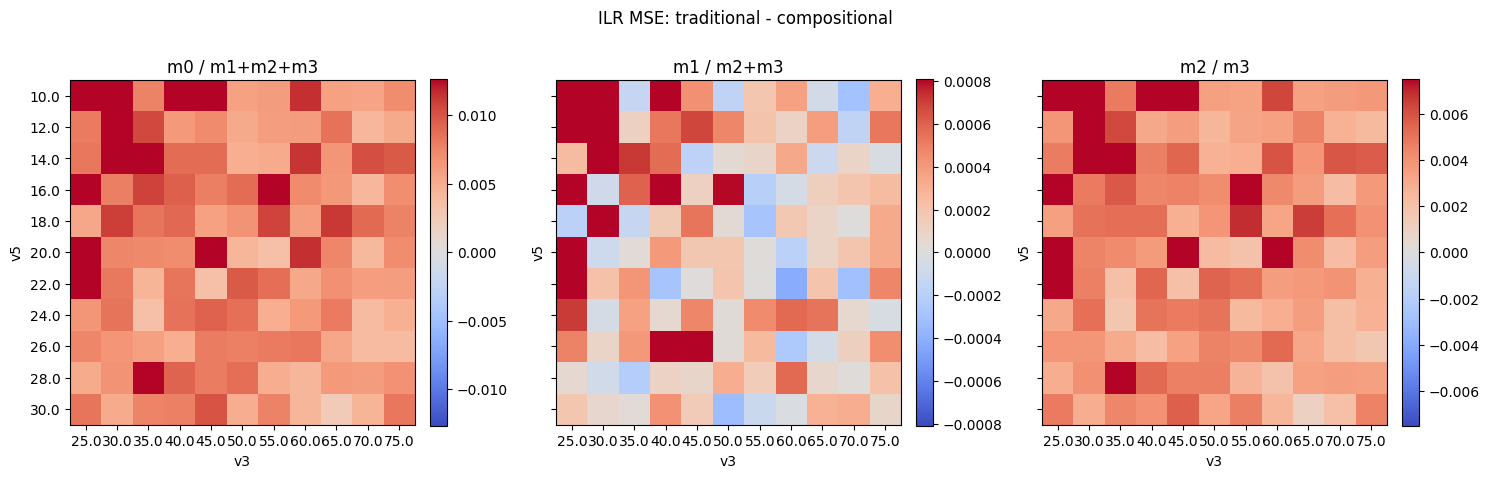

In [29]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=[15, 5])

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (ilr_resid_trad ** 2).mean(axis=1) - (ilr_resid_ilr ** 2).mean(axis=1)

ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"{ratio_lhs_i} / {ratio_rhs_i}" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


for i, label in enumerate(labels):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=label)
f.suptitle("ILR MSE: traditional - compositional", y=0.96);
f.tight_layout()

**Figure caption** Traditional vs Compositional I-MFA isotopologue estimates on a toy model. Note that compositional I-MFA is far better than traditional I-MFA at estimating ratios that are sensitive to the low-abundance isotopologues m0 and m3.